# QRShield v2 — 4/4: Adversarial Robustness, Result Tables and Limitations

This notebook (a) runs FGSM and PGD against the final `v2` EfficientNetB0 models, (b) aggregates every result file into tables (mean ± std over seeds) and a figure, and (c) records the environment for reproducibility.

**Adversarial protocol.** White-box, digital attacks on in-distribution test images; L∞ budgets 0, 1, 2, 4, 8 (/255); PGD with 10 steps and step size eps/4. The model is undefended, so strong degradation is expected; the experiment documents robustness, it does not claim any.

In [ ]:
# ── Common setup (identical in all four notebooks) ───────────────────────────
import os, gc, sys, json, time, glob, shutil, subprocess, warnings, zipfile
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running on Colab

SMOKE = False         # False = FULL study (default). True = quick pipeline check on a small slice (separate output folders).
SMOKE_ROWS = 3000     # number of manifest rows used in smoke mode
SEEDS = [0, 1, 2]
IMG = 224
FAMILIES = ['sticker_overlay', 'module_corruption', 'patch_overlay', 'logo_manipulation', 'occlusion_warp']
V1_FAMILIES = ['module_corruption', 'patch_overlay']        # the two tamper families v1 was trained on
METHODS = ['v1', 'aug', 'v2', 'freq', 'dino']

ROOT = Path(os.environ.get('QR_ROOT', '/content/drive/MyDrive/qrshield_v2'))
D = Path(os.environ.get('QR_DATA', '/content/qrshield_v2_data'))          # local copy of the dataset
ZIPS = Path(os.environ.get('QR_ZIPS', '/content/zips'))
OUT = ROOT / ('v2_eval_smoke' if SMOKE else 'v2_eval')
FEA, RES, MOD, TAB = (OUT / n for n in ('feats', 'results', 'models', 'tables'))
for p in (FEA, RES, MOD, TAB):
    p.mkdir(parents=True, exist_ok=True)
print('MODE:', 'SMOKE (small slice, NOT the real study)' if SMOKE else 'FULL study', f'| outputs -> {OUT}')

Mounted at /content/drive
MODE: FULL study | outputs -> /content/drive/MyDrive/qrshield_v2/v2_eval


In [ ]:
# ── Data: copy shards to the local disk, extract, merge the manifest ─────────
def prepare_data():
    if (D / '.done').exists():
        return
    D.mkdir(parents=True, exist_ok=True)
    ZIPS.mkdir(parents=True, exist_ok=True)
    src = sorted(glob.glob(str(ROOT / 'shard500' / 'shard_*.zip')))
    assert src, f'No shard_*.zip found in {ROOT / "shard500"}'
    for z in src:                                   # bulk copy Drive -> local disk (fast), verified by file size
        dst = ZIPS / Path(z).name
        size = os.path.getsize(z)
        for attempt in range(3):
            if dst.exists() and dst.stat().st_size == size:
                break
            shutil.copy(z, dst)                     # (re)copy; a half-copied file is never trusted
        else:
            raise RuntimeError(f'{Path(z).name}: copy incomplete after 3 tries (Drive {size} bytes, local {dst.stat().st_size}). '
                               'If Drive itself shows a smaller/odd size, this shard is broken: delete it on Drive and rebuild it.')
    zips = sorted(glob.glob(str(ZIPS / 'shard_*.zip')))
    tops = set()                                    # create the target folders first: two parallel unzips
    for z in zips:                                  # must never race to create the same directory
        with zipfile.ZipFile(z) as zz:
            tops |= {n.split('/')[0] for n in zz.namelist() if '/' in n}
    for t in tops:
        (D / t).mkdir(parents=True, exist_ok=True)
    def unz(z):
        for attempt in range(2):
            r = subprocess.run(['unzip', '-q', '-o', z, '-x', 'manifest.csv', '-d', str(D)], capture_output=True, text=True)
            if r.returncode in (0, 1):              # 1 = harmless warning
                return
        raise RuntimeError(f'unzip failed for {Path(z).name} (code {r.returncode}): {(r.stderr or r.stdout).strip()}')
    with ThreadPoolExecutor(2) as ex:
        list(ex.map(unz, zips))
    parts = []
    for z in zips:
        with zipfile.ZipFile(z) as zz:
            parts.append(pd.read_csv(zz.open('manifest.csv'), keep_default_na=False))
    merged = pd.concat(parts, ignore_index=True)
    merged.to_csv(D / 'manifest.csv', index=False)
    shutil.rmtree(ZIPS, ignore_errors=True)         # free local disk
    (D / '.done').write_text('ok')
    print('shards:', len(zips), '| manifest rows:', len(merged))

prepare_data()

man = pd.read_csv(D / 'manifest.csv', keep_default_na=False)
if SMOKE:
    man = man.iloc[:SMOKE_ROWS].copy()
need = ['image', 'set', 'split', 'base_id', 'cls', 'family', 'camera']
miss = [c for c in need if c not in man.columns]
assert not miss, f'manifest is missing columns {miss}; found {man.columns.tolist()}'

man['fp'] = str(D) + '/' + man['image'].astype(str)
man['cls_'] = man['cls'].astype(str)
man['label'] = (~man.cls_.str.startswith('benign')).astype(int)
man['fam'] = np.where(man.label == 1, man.cls_.str.replace('^tamper_', '', regex=True), 'benign')
man['base'] = man['base_id'].astype(str)
man['split_'] = man['split'].astype(str)
man['set_'] = man['set'].astype(str)
man['has_cam'] = man['camera'].astype(str).str.strip().str.lower().eq('true')
man['fidx'] = np.arange(len(man))

missing = [p for p in man.fp if not os.path.exists(p)]
assert not missing, f'{len(missing)} image files missing, e.g. {missing[:3]}'
assert set(man.fam.unique()) - {'benign'} == set(FAMILIES), man.fam.unique()

main = man[man.set_ == 'main']
tr = main[main.split_ == 'train']
va = main[main.split_ == 'val']
te = main[main.split_ == 'test']
cam = man[man.set_ == 'camera_bench']
# integrity checks: group split (no base QR in two splits); benchmark only from test bases
assert not set(tr.base) & set(te.base) and not set(tr.base) & set(va.base) and not set(va.base) & set(te.base)
assert not set(cam.base) & set(tr.base) and not set(cam.base) & set(va.base)
share = main.groupby('label').has_cam.mean()
assert 0.3 < share.min() and share.max() < 0.5, f'camera-layer share should be ~0.4 for both labels: {share.to_dict()}'
print(f'rows={len(man)} | main={len(main)} (train {len(tr)} / val {len(va)} / test {len(te)}) | camera_bench={len(cam)}')
print('camera-layer share by label:', share.round(3).to_dict())
if not SMOKE:   # safeguard: the full study must see the whole dataset
    assert len(man) > 60000 and len(tr) > 35000, f'FULL mode expects ~66,000 rows / ~42,000 train images, got {len(man)} / {len(tr)}. Check that all 24 shards are in {ROOT / "shard500"}.'

shards: 24 | manifest rows: 66083
rows=66083 | main=60000 (train 41958 / val 5810 / test 12232) | camera_bench=6083
camera-layer share by label: {0: 0.404, 1: 0.401}


In [ ]:
# ── Metrics and result storage ────────────────────────────────────────────────
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, balanced_accuracy_score

def pick_th(y, p):
    """Decision threshold chosen on the validation set (maximises balanced accuracy)."""
    ths = np.linspace(0.02, 0.98, 97)
    return float(ths[int(np.argmax([balanced_accuracy_score(y, p > t) for t in ths]))])

def m_row(y, p, th):
    y = np.asarray(y)
    return dict(n=int(len(y)), acc=accuracy_score(y, p > th), bal_acc=balanced_accuracy_score(y, p > th),
                auroc=roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
                f1=f1_score(y, p > th, zero_division=0), acc05=accuracy_score(y, p > 0.5))

def family_records(df, p, th, test, meta):
    """One record for ALL images plus one per tamper family. For a family, the benign images are
    subsampled (fixed seed) to the same size, so accuracy / F1 are not distorted by class imbalance."""
    df = df.reset_index(drop=True)
    ben = np.where(df.label.values == 0)[0]
    groups = [('ALL', np.arange(len(df)))]
    for f in sorted(df.fam[df.label == 1].unique()):
        idx = np.where(df.fam.values == f)[0]
        b = np.random.default_rng(123).choice(ben, size=min(len(idx), len(ben)), replace=False)
        groups.append((f, np.concatenate([b, idx])))
    return [dict(meta, test=test, family=f, th=th, **m_row(df.label.values[i], p[i], th)) for f, i in groups]

def rpath(key): return RES / f'{key}.json'
def done(key): return rpath(key).exists()

def finish(key, score, th, tests, meta):
    recs = []
    for name, df in tests.items():
        recs += family_records(df, score(df), th, name, meta)
    tmp = RES / f'{key}.tmp'
    json.dump(recs, open(tmp, 'w'))
    os.replace(tmp, rpath(key))                      # atomic: a half-written result never counts as done

def tests_final():
    return {'indist': te, 'camera_bench': cam}

def tests_lofo(held):
    return {'indist_heldout': pd.concat([te[te.label == 0], te[te.fam == held]]),
            'camera_heldout': pd.concat([cam[cam.label == 0], cam[cam.fam == held]])}

def v1_subset(df):
    """v1-style training data: plain benign + the two v1 tamper families, no camera layer."""
    return df[(df.fam.isin(V1_FAMILIES) | (df.cls_ == 'benign_plain')) & ~df.has_cam]

def show_status():
    names = [f.stem for f in RES.glob('*__s*.json')]
    print('finished jobs per method:', pd.Series([n.split('__')[0] for n in names]).value_counts().to_dict())

## Adversarial robustness

In [ ]:
# ── Adversarial robustness (FGSM / PGD) on the final v2 EfficientNet ─────────
import tensorflow as tf
from PIL import Image
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)

ADV_N = 1500                       # test images attacked per seed
EPS = (0, 1, 2, 4, 8)              # L-infinity budget on the 0-255 pixel scale (eps=4 means 4/255)
PGD_STEPS = 10

def load_uint8(df):
    def rd(p):
        im = Image.open(p).convert('RGB')
        if im.size != (IMG, IMG):
            im = im.resize((IMG, IMG), Image.BILINEAR)
        return np.asarray(im, np.uint8)
    with ThreadPoolExecutor(4) as ex:
        return np.stack(list(ex.map(rd, df.fp.values)))

def adv_eval(seed, n=ADV_N, eps_list=EPS, steps=PGD_STEPS, bs=25):
    out = RES / f'adversarial_s{seed}.csv'
    rows = pd.read_csv(out).to_dict('records') if out.exists() else []
    have = {(r['attack'], r['eps']) for r in rows}
    todo = [(k, e) for k in ('FGSM', 'PGD') for e in eps_list if (k, e) not in have]
    if not todo:
        return
    model = tf.keras.models.load_model(str(MOD / f'v2_s{seed}.keras'))
    th = json.load(open(MOD / f'v2_s{seed}.json'))['th']
    sub = te.sample(min(n, len(te)), random_state=0)
    X, Y = load_uint8(sub), sub.label.values.astype('float32')
    bce = tf.keras.losses.BinaryCrossentropy(reduction='none')
    rng = np.random.default_rng(seed)

    def grad(x, y):
        x = tf.convert_to_tensor(x)
        with tf.GradientTape() as t:
            t.watch(x)
            loss = bce(y[:, None], model(x, training=False))
        return t.gradient(loss, x).numpy()

    def run(kind, eps):
        ps = []
        for i in range(0, len(X), bs):                 # batch-wise: never holds the whole attacked set in RAM
            x0, y = X[i:i + bs].astype(np.float32), Y[i:i + bs]
            if eps == 0:
                x = x0
            elif kind == 'FGSM':
                x = np.clip(x0 + eps * np.sign(grad(x0, y)), 0, 255)
            else:
                x = np.clip(x0 + rng.uniform(-eps, eps, x0.shape).astype(np.float32), 0, 255)
                for _ in range(steps):
                    x = x + (eps / 4) * np.sign(grad(x, y))
                    x = np.clip(np.clip(x, x0 - eps, x0 + eps), 0, 255)
            ps.append(model(tf.convert_to_tensor(x), training=False).numpy().ravel())
        return np.concatenate(ps)

    for kind, eps in todo:
        p = run(kind, eps)
        rows.append(dict(seed=seed, attack=kind, eps=eps, n=len(Y), acc=accuracy_score(Y, p > th),
                         auroc=roc_auc_score(Y, p), tamper_missed=float(np.mean(p[Y == 1] <= th))))
        pd.DataFrame(rows).to_csv(out, index=False)    # saved after every attack setting (resumable)
        print(rows[-1], flush=True)
    del model
    tf.keras.backend.clear_session(); gc.collect()

for s in SEEDS:
    if (MOD / f'v2_s{s}.keras').exists():
        adv_eval(s)
    else:
        print(f'seed {s}: no saved v2 model yet (run notebook 3)')

adv_files = sorted(RES.glob('adversarial_s*.csv'))
if adv_files:
    A = pd.concat([pd.read_csv(f) for f in adv_files])
    summ = A.groupby(['attack', 'eps'])[['acc', 'auroc', 'tamper_missed']].agg(['mean', 'std']).round(3)
    summ.to_csv(TAB / 'adversarial_summary.csv')
    display(summ)

{'seed': 0, 'attack': 'FGSM', 'eps': 0, 'n': 1500, 'acc': 0.9386666666666666, 'auroc': np.float64(0.9658901992998103), 'tamper_missed': 0.10408432147562582}
{'seed': 0, 'attack': 'FGSM', 'eps': 1, 'n': 1500, 'acc': 0.342, 'auroc': np.float64(0.39581610863075395), 'tamper_missed': 0.4453227931488801}
{'seed': 0, 'attack': 'FGSM', 'eps': 2, 'n': 1500, 'acc': 0.26066666666666666, 'auroc': np.float64(0.2112144148757421), 'tamper_missed': 0.5454545454545454}
{'seed': 0, 'attack': 'FGSM', 'eps': 4, 'n': 1500, 'acc': 0.224, 'auroc': np.float64(0.13369658564166573), 'tamper_missed': 0.5981554677206851}
{'seed': 0, 'attack': 'FGSM', 'eps': 8, 'n': 1500, 'acc': 0.23533333333333334, 'auroc': np.float64(0.12488020497173814), 'tamper_missed': 0.5731225296442688}
{'seed': 0, 'attack': 'PGD', 'eps': 0, 'n': 1500, 'acc': 0.9386666666666666, 'auroc': np.float64(0.9658901992998103), 'tamper_missed': 0.10408432147562582}
{'seed': 0, 'attack': 'PGD', 'eps': 1, 'n': 1500, 'acc': 0.19, 'auroc': np.float64(0

acc         auroc        tamper_missed       
             mean    std   mean    std          mean    std
attack eps                                                 
FGSM   0    0.937  0.006  0.966  0.000         0.106  0.013
       1    0.350  0.014  0.408  0.021         0.437  0.026
       2    0.269  0.013  0.224  0.022         0.542  0.020
       4    0.237  0.019  0.146  0.022         0.586  0.031
       8    0.256  0.032  0.139  0.028         0.548  0.049
PGD    0    0.937  0.006  0.966  0.000         0.106  0.013
       1    0.193  0.006  0.087  0.009         0.628  0.012
       2    0.045  0.004  0.007  0.002         0.910  0.007
       4    0.006  0.003  0.006  0.002         0.987  0.005
       8    0.007  0.003  0.005  0.002         0.986  0.006

## Result tables and figure

records: 360 | seeds per method: {'aug': 3, 'dino': 3, 'freq': 3, 'v1': 3, 'v2': 3}

=== FINAL MODELS | test=indist | auroc (mean ± std) ===


method,v1,aug,v2,freq,dino
family,,,,,
ALL,0.616 ± 0.001,0.623 ± 0.002,0.969 ± 0.001,0.818 ± 0.001,0.960 ± 0.002
sticker_overlay,0.412 ± 0.005,0.383 ± 0.012,0.999 ± 0.000,0.957 ± 0.000,0.998 ± 0.001
module_corruption,0.571 ± 0.004,0.576 ± 0.004,0.876 ± 0.004,0.601 ± 0.001,0.863 ± 0.002
patch_overlay,0.845 ± 0.008,0.837 ± 0.005,1.000 ± 0.000,0.890 ± 0.003,0.999 ± 0.000
logo_manipulation,0.703 ± 0.013,0.780 ± 0.005,0.989 ± 0.001,0.819 ± 0.001,0.961 ± 0.006
occlusion_warp,0.546 ± 0.003,0.540 ± 0.003,0.981 ± 0.002,0.829 ± 0.002,0.978 ± 0.003



=== FINAL MODELS | test=indist | acc (mean ± std) ===


method,v1,aug,v2,freq,dino
family,,,,,
ALL,0.601 ± 0.001,0.599 ± 0.002,0.940 ± 0.004,0.747 ± 0.004,0.917 ± 0.002
sticker_overlay,0.608 ± 0.003,0.466 ± 0.004,0.987 ± 0.002,0.880 ± 0.002,0.977 ± 0.003
module_corruption,0.584 ± 0.000,0.593 ± 0.006,0.817 ± 0.014,0.556 ± 0.005,0.779 ± 0.009
patch_overlay,0.626 ± 0.001,0.696 ± 0.005,0.994 ± 0.001,0.812 ± 0.007,0.980 ± 0.001
logo_manipulation,0.621 ± 0.001,0.686 ± 0.003,0.955 ± 0.003,0.736 ± 0.005,0.908 ± 0.005
occlusion_warp,0.582 ± 0.003,0.561 ± 0.004,0.952 ± 0.005,0.753 ± 0.006,0.949 ± 0.002



=== FINAL MODELS | test=indist | f1 (mean ± std) ===


method,v1,aug,v2,freq,dino
family,,,,,
ALL,0.705 ± 0.001,0.666 ± 0.001,0.937 ± 0.004,0.718 ± 0.005,0.913 ± 0.002
sticker_overlay,0.706 ± 0.003,0.490 ± 0.008,0.987 ± 0.002,0.884 ± 0.002,0.978 ± 0.003
module_corruption,0.684 ± 0.000,0.655 ± 0.007,0.782 ± 0.019,0.371 ± 0.004,0.729 ± 0.015
patch_overlay,0.728 ± 0.001,0.766 ± 0.003,0.994 ± 0.001,0.805 ± 0.008,0.980 ± 0.001
logo_manipulation,0.724 ± 0.001,0.756 ± 0.001,0.953 ± 0.003,0.704 ± 0.008,0.902 ± 0.005
occlusion_warp,0.689 ± 0.003,0.623 ± 0.005,0.950 ± 0.005,0.728 ± 0.006,0.948 ± 0.002


... (10 outputs left out)


=== UNSEEN TAMPER FAMILIES | f1 | * = family was in the training set of v1/aug ===


,v1,aug,v2,freq,dino,"v2 (seen, final)"
sticker_overlay,0.706 ± 0.003,0.490 ± 0.008,0.818 ± 0.014,0.745 ± 0.012,0.838 ± 0.015,0.987 ± 0.002
module_corruption,0.684 ± 0.000*,0.655 ± 0.007*,0.252 ± 0.011,0.324 ± 0.010,0.162 ± 0.017,0.782 ± 0.019
patch_overlay,0.728 ± 0.001*,0.766 ± 0.003*,0.984 ± 0.005,0.739 ± 0.002,0.970 ± 0.003,0.994 ± 0.001
logo_manipulation,0.724 ± 0.001,0.756 ± 0.001,0.472 ± 0.037,0.612 ± 0.007,0.556 ± 0.060,0.953 ± 0.003
occlusion_warp,0.689 ± 0.003,0.623 ± 0.005,0.805 ± 0.020,0.652 ± 0.020,0.825 ± 0.010,0.950 ± 0.005
AVERAGE (unseen families),0.706 ± 0.002,0.623 ± 0.004,0.666 ± 0.002,0.614 ± 0.007,0.670 ± 0.005,NaN



=== Threshold diagnostic (in-distribution, ALL): accuracy at validation threshold vs at 0.5 ===


,acc,acc05,auroc
method,,,
aug,0.599,0.597,0.623
dino,0.917,0.915,0.960
freq,0.747,0.746,0.818
v1,0.601,0.585,0.616
v2,0.940,0.935,0.969


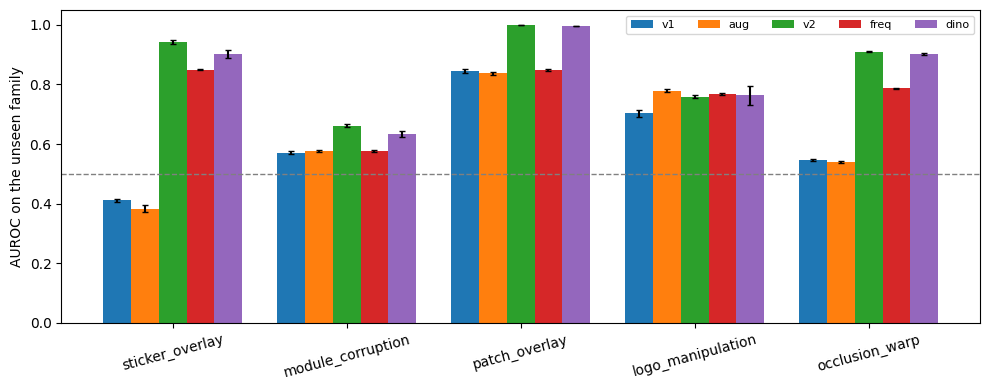

In [ ]:
# ── Aggregate all results: mean ± std over seeds ──────────────────────────────
import matplotlib.pyplot as plt

recs = []
for f in RES.glob('*__s*.json'):
    recs += json.load(open(f))
R = pd.DataFrame(recs)
assert len(R), 'No results found. Run notebooks 2 and 3 first.'
print('records:', len(R), '| seeds per method:', R.groupby('method').seed.nunique().to_dict())

def ms(x):
    return f'{x.mean():.3f} ± {x.std():.3f}' if len(x) > 1 else f'{x.mean():.3f}'

def final_table(test, metric):
    d = R[(R.setting == 'final') & (R.test == test)]
    if d.empty:
        return None
    t = d.groupby(['family', 'method'])[metric].agg(ms).unstack('method')
    t = t.reindex(columns=[m for m in METHODS if m in t.columns])
    return t.reindex(['ALL'] + [f for f in FAMILIES if f in t.index])

for test in ['indist', 'camera_bench']:
    for metric in ['auroc', 'acc', 'f1']:
        t = final_table(test, metric)
        if t is not None:
            print(f'\n=== FINAL MODELS | test={test} | {metric} (mean ± std) ===')
            display(t)
            t.to_csv(TAB / f'final_{test}_{metric}.csv')

def lofo_vals(m, f, metric):
    """Per-seed values on an UNSEEN family f. v1/aug: families outside v1's training set are unseen by
    construction. v2/freq/dino: from the leave-one-family-out runs."""
    if m in ('v1', 'aug'):
        q = R[(R.method == m) & (R.setting == 'final') & (R.test == 'indist') & (R.family == f)]
    else:
        q = R[(R.method == m) & (R.setting == f'lofo_{f}') & (R.test == 'indist_heldout') & (R.family == f)]
    return q.set_index('seed')[metric]

def unseen_table(metric):
    cols = {}
    for m in METHODS:
        col = {}
        for f in FAMILIES:
            v = lofo_vals(m, f, metric)
            if len(v):
                col[f] = ms(v) + ('*' if m in ('v1', 'aug') and f in V1_FAMILIES else '')
        use = [f for f in FAMILIES if m not in ('v1', 'aug') or f not in V1_FAMILIES]
        per_seed = pd.concat([lofo_vals(m, f, metric) for f in use], axis=1).mean(axis=1) if use else pd.Series(dtype=float)
        if len(per_seed.dropna()):
            col['AVERAGE (unseen families)'] = ms(per_seed.dropna())
        cols[m] = col
    cols['v2 (seen, final)'] = {f: ms(R[(R.method == 'v2') & (R.setting == 'final') & (R.test == 'indist') & (R.family == f)][metric])
                                for f in FAMILIES if len(R[(R.method == 'v2') & (R.setting == 'final') & (R.test == 'indist') & (R.family == f)])}
    return pd.DataFrame(cols)

for metric in ['auroc', 'bal_acc', 'f1']:
    t = unseen_table(metric)
    print(f'\n=== UNSEEN TAMPER FAMILIES | {metric} | * = family was in the training set of v1/aug ===')
    display(t)
    t.to_csv(TAB / f'unseen_{metric}.csv')

print('\n=== Threshold diagnostic (in-distribution, ALL): accuracy at validation threshold vs at 0.5 ===')
diag = R[(R.setting == 'final') & (R.test == 'indist') & (R.family == 'ALL')].groupby('method')[['acc', 'acc05', 'auroc']].mean().round(3)
display(diag)

# figure: AUROC on unseen families
fig, ax = plt.subplots(figsize=(10, 4)); w = 0.16
for j, m in enumerate(METHODS):
    vals = [lofo_vals(m, f, 'auroc') for f in FAMILIES]
    mu = [v.mean() if len(v) else np.nan for v in vals]
    sd = [v.std() if len(v) > 1 else 0 for v in vals]
    ax.bar(np.arange(len(FAMILIES)) + j * w, mu, w, yerr=sd, capsize=2, label=m)
ax.axhline(0.5, ls='--', c='gray', lw=1)
ax.set_xticks(np.arange(len(FAMILIES)) + 2 * w); ax.set_xticklabels(FAMILIES, rotation=15)
ax.set_ylabel('AUROC on the unseen family'); ax.set_ylim(0, 1.05); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(TAB / 'unseen_auroc.png', dpi=200); plt.show()

## Reproducibility record

In [ ]:
# ── Reproducibility record ────────────────────────────────────────────────────
import sklearn, platform
info = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
            tensorflow=tf.__version__, smoke=SMOKE, seeds=SEEDS, img=IMG,
            n_main=len(main), n_train=len(tr), n_val=len(va), n_test=len(te), n_camera_bench=len(cam))
try:
    info['dino_config'] = json.load(open(OUT / 'dino_config.json'))
except FileNotFoundError:
    pass
json.dump(info, open(TAB / 'run_info.json', 'w'), indent=2)
print(json.dumps(info, indent=2))

{
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "tensorflow": "2.21.0",
  "smoke": false,
  "seeds": [
    0,
    1,
    2
  ],
  "img": 224,
  "n_main": 60000,
  "n_train": 41958,
  "n_val": 5810,
  "n_test": 12232,
  "n_camera_bench": 6083,
  "dino_config": {
    "feature_set": "cls+mean",
    "val_lofo_auroc": {
      "cls+mean": 0.8361440606889422,
      "cls+mean+max": 0.8336730828482033,
      "all4": 0.8325302546475021
    }
  }
}


In [ ]:
# ── Diagnostic: where does v1 lose? One factor at a time, on the test set ─────
# The headline v1-vs-v2 gap mixes several differences (camera layer, styled/logo benign codes, unseen tamper families).
# Here each factor is isolated, using the saved final models (no retraining).
ANALYSIS = ['v1', 'aug', 'v2']
T = te.reset_index(drop=True)
mpaths = {f'{m}_s{s}': MOD / f'{m}_s{s}.keras' for m in ANALYSIS for s in SEEDS if (MOD / f'{m}_s{s}.keras').exists()}
assert mpaths, 'No saved final models found. Run notebook 3 first.'

cache = RES / 'analysis_preds.npz'
P = None
if cache.exists():
    z = np.load(cache)
    if all(k in z.files and len(z[k]) == len(T) for k in mpaths):
        P = {k: z[k] for k in mpaths}
if P is None:
    models = {k: tf.keras.models.load_model(str(p)) for k, p in mpaths.items()}
    out = {k: [] for k in models}
    for i in range(0, len(T), 1000):                      # each image is read once, scored by every model
        X = load_uint8(T.iloc[i:i + 1000]).astype(np.float32)
        for k, mdl in models.items():
            out[k].append(mdl.predict(X, batch_size=128, verbose=0).ravel())
    P = {k: np.concatenate(v) for k, v in out.items()}
    np.savez(cache, **P)
    del models; tf.keras.backend.clear_session(); gc.collect()
TH = {k: json.load(open(MOD / f'{k}.json'))['th'] for k in mpaths}

def _ms(x):
    x = pd.Series(x).dropna()
    return 'n/a' if not len(x) else (f'{x.mean():.3f} ± {x.std():.3f}' if len(x) > 1 else f'{x.mean():.3f}')

def safe_auc(p, neg, pos):
    if neg.sum() < 2 or pos.sum() < 2:
        return np.nan
    return roc_auc_score(np.r_[np.zeros(neg.sum()), np.ones(pos.sum())], np.r_[p[neg.values], p[pos.values]])

clean, camL = ~T.has_cam, T.has_cam
plain = T.cls_ == 'benign_plain'
styled = T.cls_.isin(['benign_styled', 'benign_styled_logo'])
v1f = T.fam.isin(V1_FAMILIES)
unseen = T.fam.isin([f for f in FAMILIES if f not in V1_FAMILIES])
FACTORS = {
    'A. home turf: plain benign vs module/patch, no camera layer': (plain & clean, v1f & clean),
    'B. same classes, WITH camera layer (camera effect only)': (plain & camL, v1f & camL),
    'C. styled/logo benign as negatives, no camera (benign-style effect only)': (styled & clean, v1f & clean),
    'D. unseen tamper families vs plain benign, no camera (unseen-family effect only)': (plain & clean, unseen & clean),
}

# Table 1: AUROC per isolated factor
rows = []
for name, (neg, pos) in FACTORS.items():
    for k, p in P.items():
        rows.append(dict(factor=name, method=k.split('_s')[0], seed=int(k.split('_s')[1]), auroc=safe_auc(p, neg, pos)))
t1 = pd.DataFrame(rows).groupby(['factor', 'method']).auroc.agg(_ms).unstack('method')[ANALYSIS].reindex(list(FACTORS))
print('=== Table 1. AUROC by isolated factor (mean ± std over seeds) ===')
display(t1)
print('image counts (negatives / positives):', {n[:1]: (int(a.sum()), int(b.sum())) for n, (a, b) in FACTORS.items()})

# Table 2: false-positive rate on benign codes, by style and camera layer (at each model's validation threshold)
rows = []
for k, p in P.items():
    for style in ['benign_plain', 'benign_styled', 'benign_styled_logo']:
        for cond, mask in [('clean', clean), ('camera', camL)]:
            sel = ((T.cls_ == style) & mask).values
            if sel.sum():
                rows.append(dict(benign=f'{style} / {cond}', method=k.split('_s')[0], fpr=float(np.mean(p[sel] > TH[k]))))
t2 = pd.DataFrame(rows).groupby(['benign', 'method']).fpr.agg(_ms).unstack('method')[ANALYSIS]
print('\n=== Table 2. False-positive rate on benign test codes (lower is better) ===')
display(t2)

# Table 3: tamper detection rate (recall) by family, clean vs camera
rows = []
for k, p in P.items():
    for f in FAMILIES:
        for cond, mask in [('clean', clean), ('camera', camL)]:
            sel = ((T.fam == f) & mask).values
            if sel.sum():
                rows.append(dict(family=f'{f} / {cond}', method=k.split('_s')[0], recall=float(np.mean(p[sel] > TH[k]))))
t3 = pd.DataFrame(rows).groupby(['family', 'method']).recall.agg(_ms).unstack('method')[ANALYSIS]
print('\n=== Table 3. Tamper recall by family (higher is better; * v1/aug trained on module_corruption, patch_overlay) ===')
display(t3)
for i, t in enumerate([t1, t2, t3], 1):
    t.to_csv(TAB / f'diagnostic_table{i}.csv')

=== Table 1. AUROC by isolated factor (mean ± std over seeds) ===


method,v1,aug,v2
factor,,,
"A. home turf: plain benign vs module/patch, no camera layer",0.974 ± 0.001,0.959 ± 0.002,0.959 ± 0.001
"B. same classes, WITH camera layer (camera effect only)",0.869 ± 0.004,0.945 ± 0.001,0.941 ± 0.003
"C. styled/logo benign as negatives, no camera (benign-style effect only)",0.573 ± 0.009,0.521 ± 0.005,0.932 ± 0.002
"D. unseen tamper families vs plain benign, no camera (unseen-family effect only)",0.986 ± 0.001,0.860 ± 0.015,0.996 ± 0.000


image counts (negatives / positives): {'A': (1464, 1516), 'B': (973, 973), 'C': (2214, 1516), 'D': (1464, 2184)}

=== Table 2. False-positive rate on benign test codes (lower is better) ===


method,v1,aug,v2
benign,,,
benign_plain / camera,0.934 ± 0.013,0.247 ± 0.030,0.014 ± 0.012
benign_plain / clean,0.015 ± 0.002,0.010 ± 0.003,0.003 ± 0.002
benign_styled / camera,1.000 ± 0.000,0.917 ± 0.012,0.015 ± 0.006
benign_styled / clean,0.980 ± 0.001,0.822 ± 0.028,0.003 ± 0.002
benign_styled_logo / camera,1.000 ± 0.000,0.998 ± 0.001,0.067 ± 0.011
benign_styled_logo / clean,1.000 ± 0.000,0.998 ± 0.001,0.028 ± 0.008



=== Table 3. Tamper recall by family (higher is better; * v1/aug trained on module_corruption, patch_overlay) ===


method,v1,aug,v2
family,,,
logo_manipulation / camera,1.000 ± 0.000,0.969 ± 0.007,0.891 ± 0.006
logo_manipulation / clean,0.986 ± 0.001,0.976 ± 0.002,0.953 ± 0.005
module_corruption / camera,0.991 ± 0.002,0.853 ± 0.013,0.664 ± 0.053
module_corruption / clean,0.841 ± 0.002,0.719 ± 0.016,0.651 ± 0.015
occlusion_warp / camera,0.994 ± 0.004,0.743 ± 0.016,0.907 ± 0.015
occlusion_warp / clean,0.870 ± 0.008,0.710 ± 0.012,0.934 ± 0.009
patch_overlay / camera,1.000 ± 0.000,0.997 ± 0.001,0.998 ± 0.000
patch_overlay / clean,0.999 ± 0.000,0.999 ± 0.000,0.999 ± 0.000
sticker_overlay / camera,0.998 ± 0.000,0.611 ± 0.018,0.986 ± 0.013


## Limitations (to be stated in any write-up)

* **No real-camera test set.** All images are synthetic; camera effects are simulated (mild in the main set, strong in the benchmark). Real phone photos of printed and on-screen codes were not collected, so real-world performance is untested. This is the main external-validity limitation.
* **Independent work.** The study was carried out without a lab (limited compute: free/Pro Colab sessions), hence a single model family for the deep baselines and frozen features for the others.
* **v1 is a reproduction** of the v1 setting (data and recipe), not the original weights.
* **Feature methods:** seeds vary only the classifier. The DINOv2 pooling choice used validation LOFO, which sees validation images of all families (not test images).
* **Resolution.** Images are 224 × 224; very small module flips may partly vanish in downsizing (`module_corruption` is the hardest family for several methods).
* **Per-family metrics** use benign images subsampled to the family size (fixed seed); AUROC is computed on that balanced subset, so accuracy equals balanced accuracy there.
* **Adversarial results** are digital white-box attacks on undefended models, not physical attacks.
* **Decode flags** (does the tampered code still scan to the original / another payload) come from OpenCV's decoder and are stored in the manifest but not analysed here.
* **Clean substitute codes** (a freshly generated, artefact-free code) cannot be detected by an image detector; the signature layer is meant to cover that case.